# 🧪 LAB: Machine Learning to Predict Concrete Compressive Strength

In this lab, you will apply `PyTorch` to a real-world data problem. You will implement a Neural Network in `PyTorch` using the new functionalities introduced this week and compare its performance with a Support Vector Machine and Linear Regression.

Your goal is to predict the **compressive strength of concrete** (the outcome variable, *Y*) based on a set of input features (*X*), including:
**Cement, Blast Furnace Slag, Fly Ash, Water, Superplasticizer, Coarse Aggregate, Fine Aggregate, and Age.**

This dataset and problem are based on the following paper:

- I-Cheng Yeh, "Modeling of strength of high performance concrete using artificial neural networks," Cement and Concrete Research, Vol. 28, No. 12, pp. 1797-1808 (1998). [Link to the paper](yeh1998.pdf).


---

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

---

In total, this lab assignment will be worth **100 points**.

--- 
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.

NAME(s) = "Audrey, Claire, Jonathan"

## 0. Overall Instructions 

In this lab, you will work with three models: a **Neural Network**, a **Support Vector Machine (SVM)**, and some form of **Linear Regression**. Each should meet the following requirements:

- **Do not tune the models**. For example, for the Neural Network, choose any number of layers and hidden units you prefer; for the SVM, select a kernel of your choice (e.g., linear, RBF, polynomial), etc.

- **Evaluate model performance using k-fold cross-validation**. That is, run each model using a chosen number of folds (*k*), and report the average performance across all folds. You may select the value of *k* that you want.

- **Be careful with data preprocessing**. Apply all preprocessing steps properly to avoid data leakage (e.g. standardizing features before data splitting)

## 1. Pre-implementation Group Discussion (15 points)

In your group, discuss, agree on, and elaborate the following points:

- **Descriptive analysis**. Identify what exploratory or descriptive analyses you can perform to better understand the relationship between each input variable and the outcome. Consider both visual (e.g., scatter plots, histograms) and statistical summaries.

**answer** First, we will check the data for missing values and duplicate rows. Then we will look at summary statistics for every variable (mean, standard deviation, min, max and quartiles), plus how skewed each variable is and how many zeros it has, since some ingredients like slag and fly ash are not used in every mix. For the visuals, we will make a histogram of each variable to see its distribution and a scatter plot of each input against compressive strength to see if the relationship looks like a straight line, a curve, or nothing at all. Since age only takes a few values (like 3, 7, 28 and 90 days), we will also compare the strength at each age with a box plot. Then we will compute the correlation between each input and strength, using Pearson for straight-line relationships and Spearman for relationships that keep going up (or down) but not in a straight line, and we will make a correlation matrix to see which inputs are related to each other. Finally, we will check the ratio of water to binder (cement + slag + fly ash), because in concrete the amount of water compared to the binder is one of the main things that controls strength, so this shows whether inputs matter more together than one at a time.

- **Data preprocessing**. Decide what preprocessing steps are necessary given that you will be using neural networks. 

**answer** All 8 inputs are numbers, so we don't need to encode anything, but we will check for missing values and duplicate rows first. The inputs are on very different scales (for example cement goes up to 540 kg but superplasticizer only goes up to about 32 kg), so we need to standardize them, because a neural network trains much better when all the inputs are on a similar scale. To avoid data leakage, the scaler will only be fit on the training folds in each round of cross-validation and then used to transform the test fold, so the test fold never affects the scaling. For the scikit-learn models we can do this by putting the `StandardScaler` and the model together in a `Pipeline`, and for the PyTorch network we will fit a new scaler inside every fold. For PyTorch we will also convert the data to float32 tensors and use a `DataLoader` to split the training data into batches.

- **Model configuration**. Specify which cost function and output layer activation are most appropriate for your problem type (e.g., regression vs. classification). Explain your reasoning based on the nature of the outcome variable.

**answer** This is a regression problem because compressive strength is a continuous number measured in MPa, so we will use mean squared error (MSE) as the cost function (`nn.MSELoss` in PyTorch). MSE squares each error, so it penalizes big mistakes more than small ones. The output layer will have one unit with no activation function (a linear output), because the prediction has to be able to take any real value. An activation like sigmoid would squash the output between 0 and 1, which would not work for strength values that go up to about 83 MPa. The hidden layers will use ReLU.

- **Performance evaluation**. Describe how you will perform k-fold cross-validation to assess your model’s performance. Include how you will divide the data, compute metrics across folds, and report the final averaged results.

**answer** We will use 5-fold cross-validation with `KFold(n_splits=5, shuffle=True, random_state=42)`. This splits the data into 5 equal parts, and in each round the model is trained on 4 parts (80% of the data) and tested on the part it did not see (20%), so every row is used as test data exactly once. Inside each round we fit the scaler on the training part only, train the model, and then compute the MSE, RMSE and R² on the test part. We won't use accuracy, since that only makes sense for classification. At the end we will report the mean and standard deviation of each metric across the 5 folds. We will use the same folds for the neural network, the scikit-learn MLP, the SVM and linear regression, so the comparison between the models is fair.

USE AS MANY MARKDOWN CELLS AS NEEDED

## 2. Descriptive analysis (10 points)

Apply the descriptive analyses that your group agreed upon in the previous section.

**Load the dataset before beginning the descriptive analysis; you will also use it in the following sections.**

### Loading the data

In [1]:
# pandas needs the xlrd package to read .xls files
%pip install -q xlrd

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# load the data and give the columns shorter names (same order as in the file)
df = pd.read_excel("Concrete_Data.xls")
df.columns = ["cement", "slag", "fly_ash", "water", "superplasticizer",
              "coarse_agg", "fine_agg", "age", "strength"]

# inputs (X) and outcome (y) for the next sections
X = df.drop(columns="strength")
y = df["strength"]

print(df.shape)
df.head()

(1030, 9)


,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age,strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


In [3]:
# check for missing values and duplicate rows
print("missing values:", df.isna().sum().sum())
print("duplicate rows:", df.duplicated().sum())

missing values: 0
duplicate rows: 25


### Summary statistics

All amounts are in kg per m³ of concrete, age is in days and strength is in MPa. We also added the skewness and the percent of rows that are 0 for each variable.

In [4]:
summary = df.describe().T
summary["skew"] = df.skew()
summary["% zeros"] = (df == 0).mean() * 100
summary.round(2)

,count,mean,std,min,25%,50%,75%,max,skew,% zeros
cement,1030.0,281.17,104.51,102.00,192.38,272.90,350.00,540.0,0.51,0.00
slag,1030.0,73.90,86.28,0.00,0.00,22.00,142.95,359.4,0.80,45.24
fly_ash,1030.0,54.19,64.00,0.00,0.00,0.00,118.27,200.1,0.54,54.95
water,1030.0,181.57,21.36,121.75,164.90,185.00,192.00,247.0,0.07,0.00
superplasticizer,1030.0,6.20,5.97,0.00,0.00,6.35,10.16,32.2,0.91,36.80
coarse_agg,1030.0,972.92,77.75,801.00,932.00,968.00,1029.40,1145.0,-0.04,0.00
fine_agg,1030.0,773.58,80.18,594.00,730.95,779.51,824.00,992.6,-0.25,0.00
age,1030.0,45.66,63.17,1.00,7.00,28.00,56.00,365.0,3.27,0.00
strength,1030.0,35.82,16.71,2.33,23.71,34.44,46.14,82.6,0.42,0.00


### Distribution of each variable

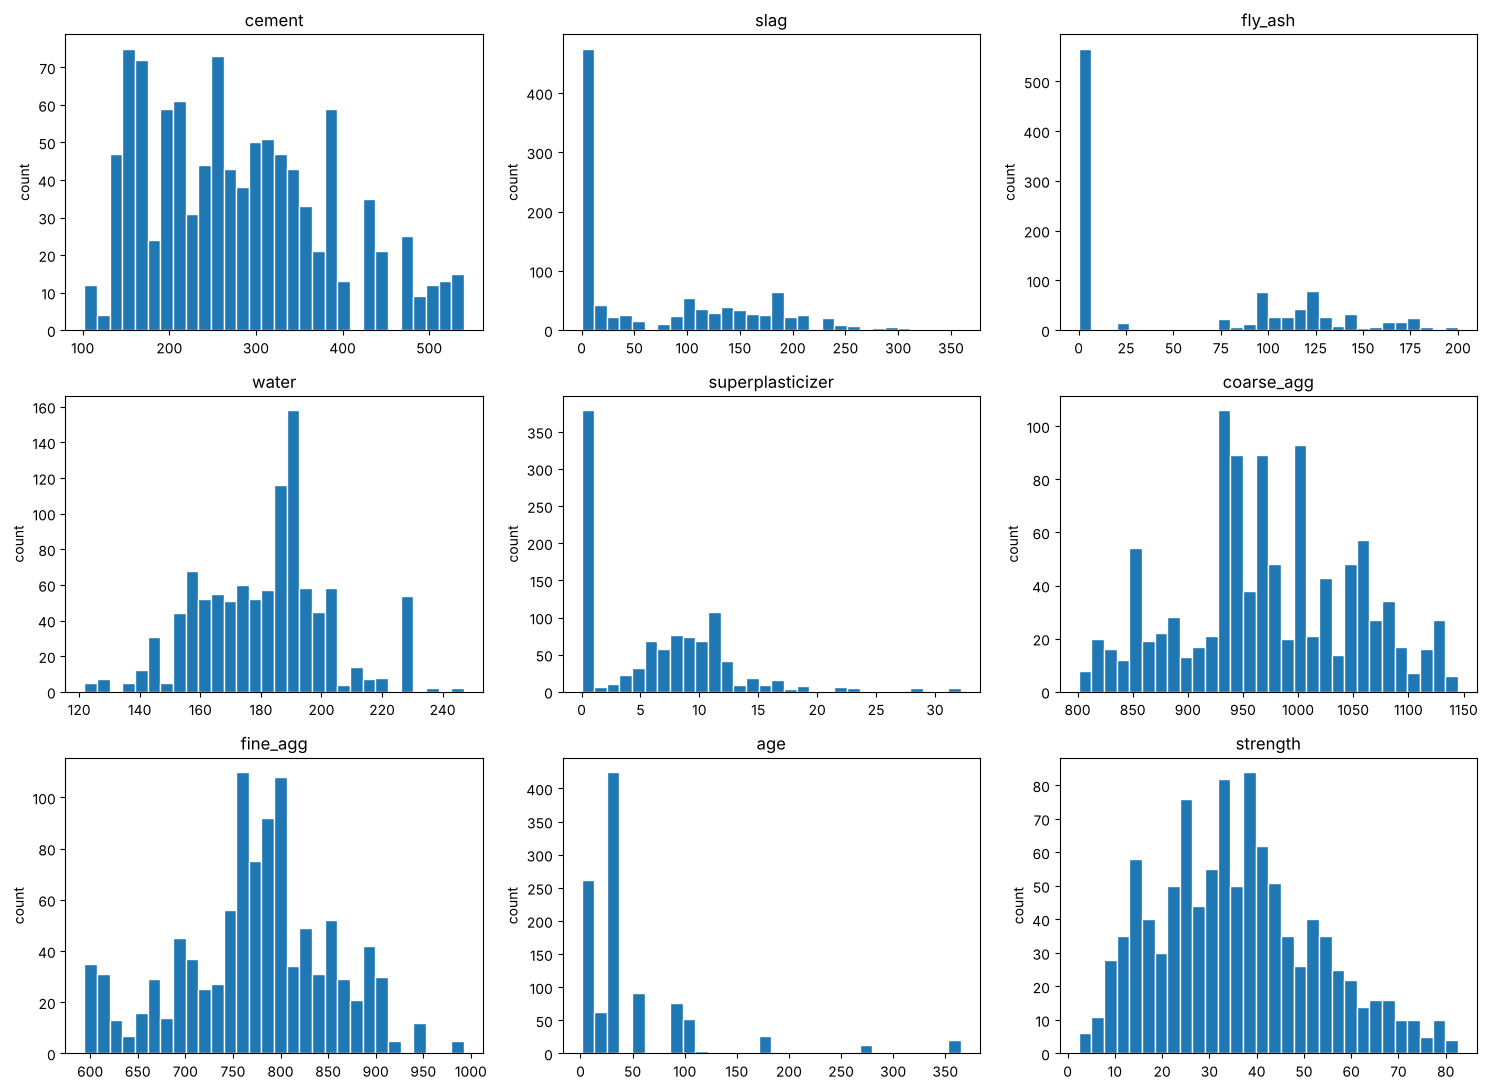

In [5]:
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, col in zip(axes.ravel(), df.columns):
    ax.hist(df[col], bins=30, edgecolor="white")
    ax.set_title(col)
    ax.set_ylabel("count")
plt.tight_layout()
plt.show()

### Each input vs. compressive strength

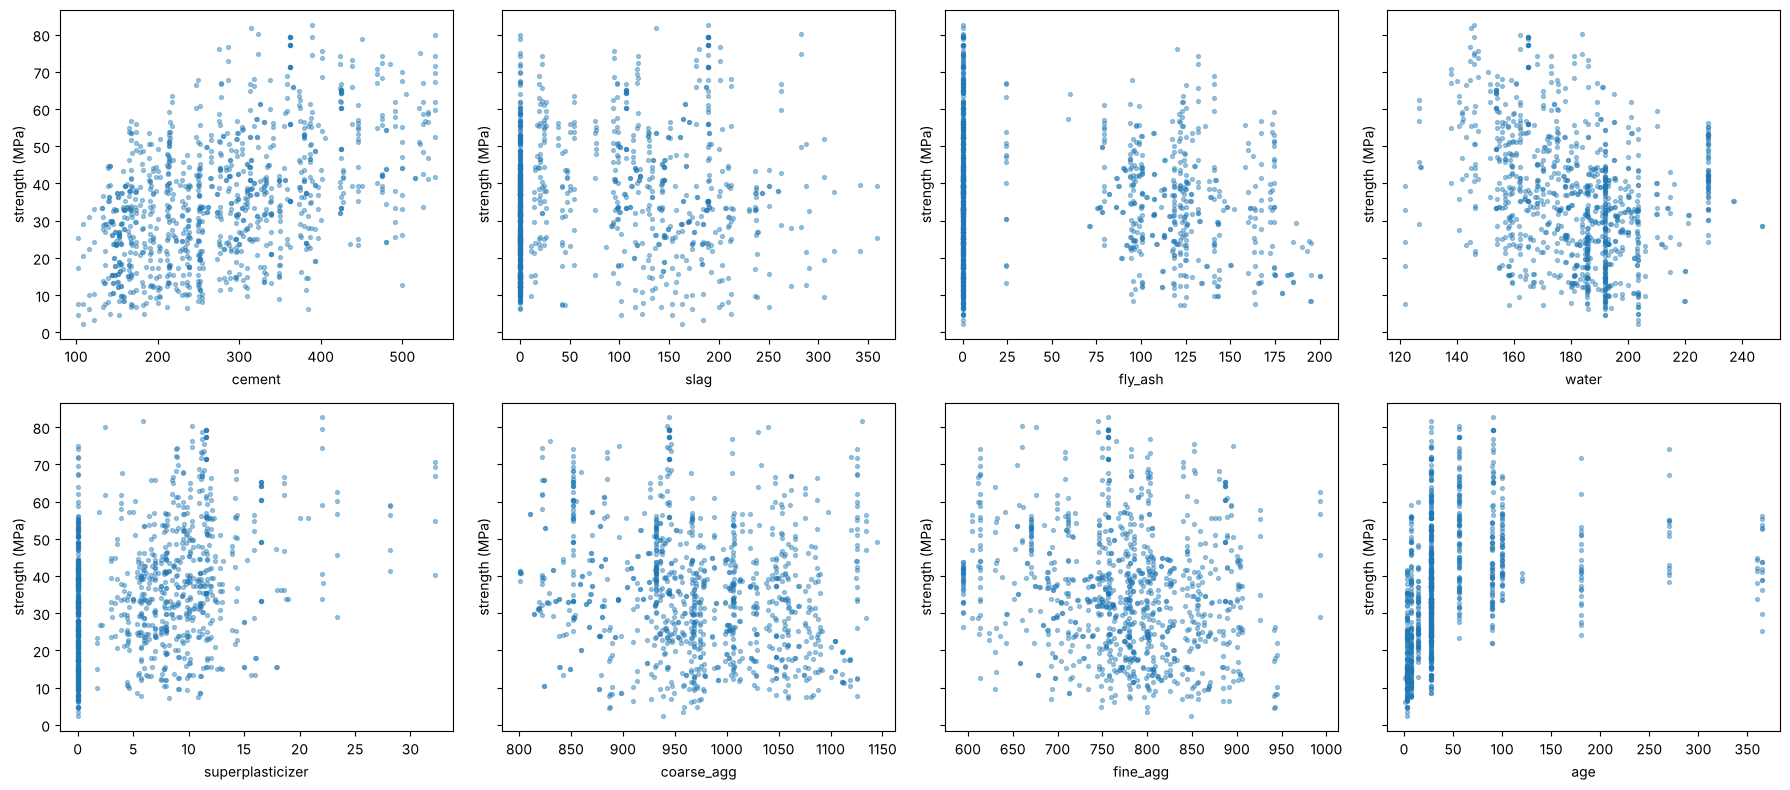

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharey=True)
for ax, col in zip(axes.ravel(), X.columns):
    ax.scatter(df[col], y, s=8, alpha=0.4)
    ax.set_xlabel(col)
    ax.set_ylabel("strength (MPa)")
plt.tight_layout()
plt.show()

age    1      3      7     14     28    56    90    91    100   120   180  \
count  2.0  134.0  126.0  62.0  425.0  91.0  54.0  22.0  52.0   3.0  26.0   
mean   9.5   19.0   26.1  28.8   36.7  51.9  40.5  69.8  47.7  39.6  41.7   

age     270   360   365  
count  13.0   6.0  14.0  
mean   51.3  40.7  43.6  


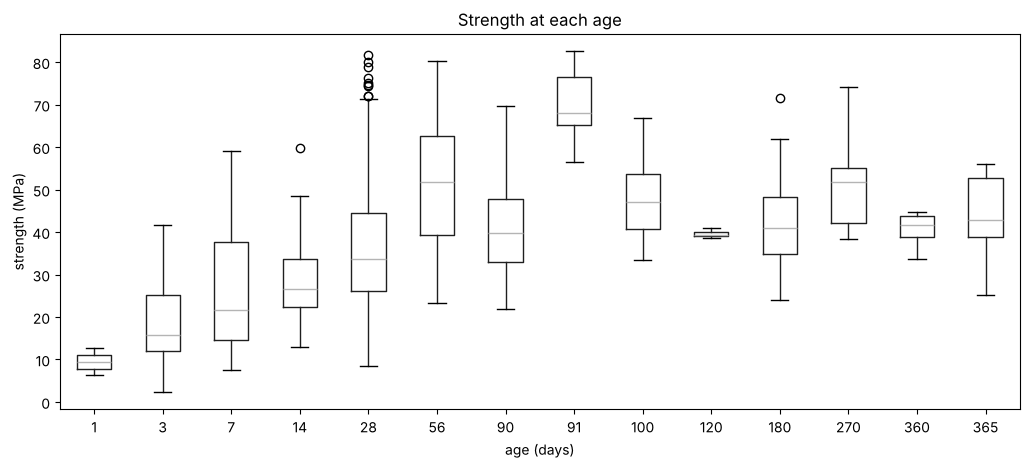

In [7]:
# age only takes 14 different values, so we compare the strength at each age
print(df.groupby("age")["strength"].agg(["count", "mean"]).round(1).T)

df.boxplot(column="strength", by="age", grid=False, figsize=(12, 5))
plt.suptitle("")
plt.title("Strength at each age")
plt.xlabel("age (days)")
plt.ylabel("strength (MPa)")
plt.show()

### Correlations

In [8]:
# correlation of each input with strength
# Pearson only measures straight-line relationships, Spearman also picks up curved ones that keep going in one direction
corr = pd.DataFrame({
    "Pearson": df.corr()["strength"],
    "Spearman": df.corr(method="spearman")["strength"],
}).drop("strength").sort_values("Pearson", ascending=False)
corr.round(3)

,Pearson,Spearman
cement,0.498,0.478
superplasticizer,0.366,0.348
age,0.329,0.596
slag,0.135,0.162
fly_ash,-0.106,-0.078
coarse_agg,-0.165,-0.184
fine_agg,-0.167,-0.180
water,-0.290,-0.308


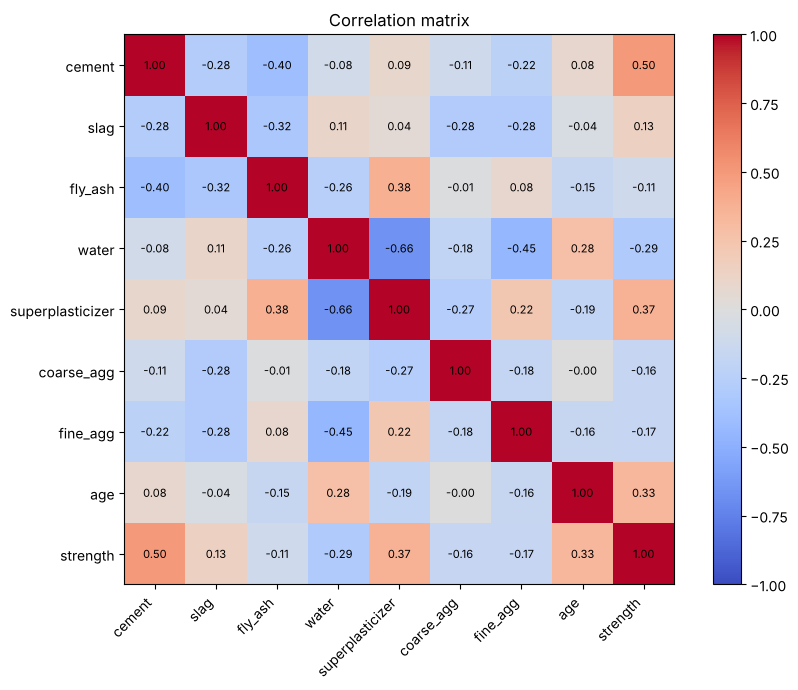

In [9]:
# correlation between every pair of variables
corr_matrix = df.corr()
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1)
fig.colorbar(im)
ax.set_xticks(range(len(df.columns)))
ax.set_xticklabels(df.columns, rotation=45, ha="right")
ax.set_yticks(range(len(df.columns)))
ax.set_yticklabels(df.columns)
for i in range(len(df.columns)):
    for j in range(len(df.columns)):
        ax.text(j, i, f"{corr_matrix.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.set_title("Correlation matrix")
plt.tight_layout()
plt.show()

correlation of strength with water/cement: -0.501
correlation of strength with water/binder: -0.623


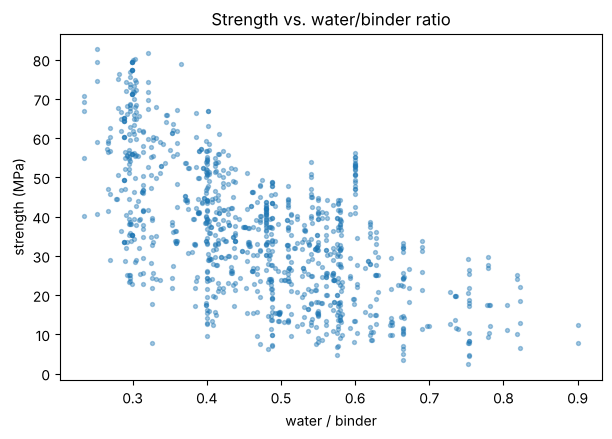

In [10]:
# inputs together: water compared to the binder (cement + slag + fly ash)
water_cement = df["water"] / df["cement"]
water_binder = df["water"] / (df["cement"] + df["slag"] + df["fly_ash"])
print("correlation of strength with water/cement:", round(water_cement.corr(y), 3))
print("correlation of strength with water/binder:", round(water_binder.corr(y), 3))

plt.figure(figsize=(7, 4.5))
plt.scatter(water_binder, y, s=8, alpha=0.4)
plt.xlabel("water / binder")
plt.ylabel("strength (MPa)")
plt.title("Strength vs. water/binder ratio")
plt.show()

### What we found

**Data quality.** The dataset has 1,030 rows with 8 inputs and the outcome. Every column is a number and there are no missing values. There are 25 rows that are exact copies of other rows. That is only about 2% of the data, so we kept them for now, but it is something to keep in mind for cross-validation, since a copy of a row could end up in both the training fold and the test fold and make the scores look a little better than they really are.

**Scales and distributions.** The inputs are on very different scales. For example, coarse aggregate goes from 801 to 1,145 kg, but superplasticizer only goes from 0 to 32.2 kg, so we need to standardize the inputs before training the neural network. Slag, fly ash and superplasticizer are 0 in about 45%, 55% and 37% of the rows, because not every mix uses those ingredients, which is why their histograms have a big spike at 0. Age is very skewed to the right (skew of 3.27). Most of the samples (749 of the 1,030) were tested at 28 days or less, and only 62 were tested after 100 days. Strength itself is roughly bell-shaped and a little skewed to the right, going from 2.33 to 82.6 MPa with a mean of 35.82 MPa.

**Each input vs. strength.** Cement has the clearest relationship with strength. More cement usually means stronger concrete, and it has the highest correlation of all the inputs (0.498). Superplasticizer (0.366) and age (0.329) are also positive, while water is negative (-0.290), so mixes with more water tend to be weaker. Slag, fly ash, coarse aggregate and fine aggregate only have weak correlations (between -0.17 and 0.14), and their scatter plots look mostly like random clouds. Even for cement the points are very spread out, so the same amount of cement can give very weak or very strong concrete. This means no single input can predict strength well on its own.

**Age is not a straight line.** Age has a Spearman correlation of 0.596 but a Pearson correlation of only 0.329. The box plot shows why. Strength goes up fast at the start (the average goes from 9.5 MPa at 1 day to 19.0 at 3 days, 26.1 at 7 days, 36.7 at 28 days and 51.9 at 56 days), but after that it levels off instead of going up in a straight line. The averages after 56 days also jump around, for example 40.5 MPa at 90 days but 69.8 MPa at 91 days. This is probably because different mixes were tested at different ages, so age is not the only thing that changes between those groups.

**The inputs are related to each other.** Water and superplasticizer have the strongest correlation of any pair (-0.66), which makes sense because superplasticizer is used so a mix needs less water. Water and fine aggregate (-0.45), and cement and fly ash (-0.40), are also negatively related.

**Inputs matter more together.** The ratio of water to binder (cement + slag + fly ash) has a correlation of -0.623 with strength, which is stronger than any single input. The scatter plot shows a clear downward trend, where less water compared to the binder means stronger concrete. Water compared to cement alone gives -0.501, so counting slag and fly ash as part of the binder makes the relationship stronger. This shows that strength depends on combinations of inputs and not just on each input by itself.

**What this means for our models.** First, the inputs have to be standardized, and to avoid data leakage the scaler has to be fit inside each cross-validation fold. Second, some relationships are curved (like age) and some inputs only make sense together (like water and binder). Linear regression can only fit a straight-line effect for each input, so it will probably miss part of the pattern. A neural network with hidden layers can learn curves and combinations of inputs on its own, so we expect it (and an SVM with a non-linear kernel) to do better than linear regression in the comparison section.

## 3. Neural Network (40 points)

Implement a neural network as you did in the previous lab, but this time leverage the new functionalities introduced this week. Specifically:

- Your class implementing the neural network should inherit from nn.Module.

- Use `nn.Linear` for the linear transformations between layers, `nn.ReLU` for the hidden-layer activations, and the appropriate activation function for the output layer (e.g., `nn.Sigmoid` for binary classification).

- Use the appropriate cost function from `torch.nn` for your task (e.g., `nn.MSELoss`, `nn.BCELoss`).

- Use Adam from `torch.optim` as the optimizer.

- Use `DataLoader` to efficiently do batch processing. You may choose the batch size freely.

Once you have implemented this class, create an instance of it, then train and evaluate your model on the lab dataset.

**Remember to follow the general requirements regarding model tuning, evaluation, and data preprocessing described earlier.**

In [11]:
# USE AS MANY CELLS AS NEEDED

## 4. Replication (10 points)

Replicate your neural network experiment using the corresponding model class from `scikit-learn`: https://scikit-learn.org/stable/api/sklearn.neural_network.html. Be sure to apply the same neural network architecture as well as the same procedures for model evaluation and preprocessing to ensure a fair comparison.

**Remember**: Follow the general requirements regarding model tuning, evaluation, and data preprocessing described earlier.

In [12]:
# USE AS MANY CELLS AS NEEDED

## 5. Comparison (20 points)

Apply a Support Vector Machine (SVM) and Linear Regression model to the dataset, and compare their performance with that of your Neural Network.

Discuss any similarities or differences you observe in their results and provide possible explanations for these patterns.

Be sure to apply the k-fold cross-validation procedure to ensure a fair comparison across all models.

**Remember**: Follow the general requirements regarding model tuning, evaluation, and data preprocessing described earlier.

In [13]:
# USE AS MANY CELLS AS NEEDED

## 6. Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

YOUR TEXT HERE